# 5. Tables and targets

Everything `lazuli-exo` computes at runtime comes out of a small directory of
`.npz` lookup tables plus a frozen target registry, and nothing heavier than
numpy is imported. This notebook opens the tables directly, so you can see what
the runtime reads and where its caveats are recorded.

```
index.json                 # schema version, planets, grids, sha256 manifest
atmo/zeta_grid.npz         # parametric model: zeta(T, [M/H], C/O, fiducial, lambda), mu
star/phoenix_grid.npz      # PHOENIX SEDs on (T_eff, log g, [Fe/H])
star/<planet-slug>.npz     # wavelength_um, f_lambda, meta      (R = 10 000 host SED)
noise/<planet-slug>.npz    # wavelength_um, depth_err_1transit, meta
ld/<planet-slug>.npz       # wavelength_um, u1, u2, meta
```

Scenarios are not files: they are presets of the parametric model. The
per-planet POSEIDON spectra the model is validated against live under
`precompute/tables/` and are not shipped.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__file__)

lazuli_exo /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/__init__.py


## Locating the tables

`resolve_tables_dir()` looks in three places, in order: an explicit
`tables_dir=` argument, then the `LAZULI_EXO_TABLES` environment variable, then
the `data/tables/` shipped inside the package.

In [2]:
from pathlib import Path
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
print(f"tables dir: {tdir}\n")

for sub in ["atmo", "star", "noise", "ld"]:
    files = sorted((tdir / sub).glob("*.npz"))
    mb = sum(f.stat().st_size for f in files) / 1e6
    print(f"  {sub:8s} {len(files):3d} files  {mb:6.2f} MB")

total = sum(f.stat().st_size for f in tdir.rglob("*")
            if f.is_file()) / 1e6
print(f"\n  {'total':8s} {total:16.2f} MB")

tables dir: /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/data/tables

  atmo       1 files   25.26 MB
  star      15 files    5.62 MB
  noise     14 files    0.14 MB
  ld        14 files    0.03 MB

  total               31.06 MB


## The index

`index.json` is the catalogue. It carries a schema `version`, and `load_index()`
refuses a mismatch rather than silently misreading tables. Since schema 4 it
also holds a sha256 manifest of every file, so a table that was edited or
truncated after generation can be caught.

In [3]:
index = tables.load_index(tdir)

print(f"schema version: {index['version']} "
      f"(supported: {tables.SCHEMA_VERSION})")
print(f"planets:        {len(index['planets'])}")
print(f"grids:          {index['atmo']}")
print(f"manifest:       {len(index['files'])} files\n")

print("index['planets']['WASP-39 b']:", index["planets"]["WASP-39 b"])

rel = "noise/wasp-39-b.npz"
print(f"\n{rel}: manifest {index['files'][rel][:16]}..., "
      f"on disk {tables.sha256_file(tdir / rel)[:16]}...")
assert tables.sha256_file(tdir / rel) == index["files"][rel]

schema version: 4 (supported: 4)
planets:        14
grids:          {'zeta_grid': True}
manifest:       44 files

index['planets']['WASP-39 b']: {'has_ld': True, 'has_noise': True, 'slug': 'wasp-39-b'}

noise/wasp-39-b.npz: manifest baf4e4a67de0a11d..., on disk baf4e4a67de0a11d...


The index is regenerated from what is on disk by `tables.rebuild_index()`,
which every precompute script calls when it finishes, so the catalogue cannot
drift from the files.

In [4]:
missing = [rel for rel in index["files"] if not (tdir / rel).exists()]
print(f"indexed files missing from disk: {missing or 'none'}")
assert not missing

bad = [rel for rel in index["files"]
       if tables.sha256_file(tdir / rel) != index["files"][rel]]
print(f"files whose hash differs from the manifest: {bad or 'none'}")
assert not bad

indexed files missing from disk: none
files whose hash differs from the manifest: none


## What each table holds

Each per-planet loader returns its arrays plus the `meta` dict that records how
the table was produced; the grid loaders return a dict. The model itself is not
a table any more: `observe()` evaluates the parametric model on the ζ grid's
wavelengths.

In [5]:
PLANET = "WASP-39 b"

obs_m = lazuli_exo.observe(PLANET, scenario="clear", tables_dir=tdir)
wl_m, depth_m = obs_m.model_wavelength, obs_m.model_depth
wl_s, flam_s, meta_s = tables.load_star(tdir, PLANET)
wl_n, err_n, meta_n = tables.load_noise(tdir, PLANET)
wl_l, u1_l, u2_l, meta_l = tables.load_ld(tdir, PLANET)
zeta = tables.load_zeta_grid(tdir)
phoenix = tables.load_phoenix_grid(tdir)

print(f"{'array':8s}{'samples':>9s}{'wavelength range (um)':>26s}")
for lab, w in [("model", wl_m), ("star", wl_s),
               ("noise", wl_n), ("ld", wl_l)]:
    print(f"{lab:8s}{w.size:9d}{w.min():14.4f} - {w.max():.4f}")

print(f"\nzeta grid: zeta{zeta['zeta'].shape} on T x [M/H] x C/O x fiducial x lambda, "
      f"{zeta['wavelength_um'].size} wavelengths")
print(f"PHOENIX:   log_flam{phoenix['log_flam'].shape} on T_eff x log g x [Fe/H] x lambda, "
      f"T_eff {phoenix['teff_K'].min():.0f}-{phoenix['teff_K'].max():.0f} K")

array     samples     wavelength range (um)
model       14430        0.3998 - 1.6925
star        16650        0.3500 - 1.8500
noise         525        0.4000 - 1.6993
ld             48        0.4061 - 1.6746

zeta grid: zeta(16, 9, 4, 2, 16650) on T x [M/H] x C/O x fiducial x lambda, 16650 wavelengths
PHOENIX:   log_flam(76, 5, 1, 2121) on T_eff x log g x [Fe/H] x lambda, T_eff 2000-12000 K


The ζ grid spans 0.35 to 1.85 µm at R = 10 000 (margin around the 0.40 to
1.70 µm IFS bandpass); `obs.model_wavelength` is the slice of it inside the
binned range, which is why the model row above starts at 0.40 µm. The noise
table is sampled at the instrument's own channel spacing. That difference is why `observe()` puts the
model through the instrument response onto the channels rather than
interpolating one grid onto the other.

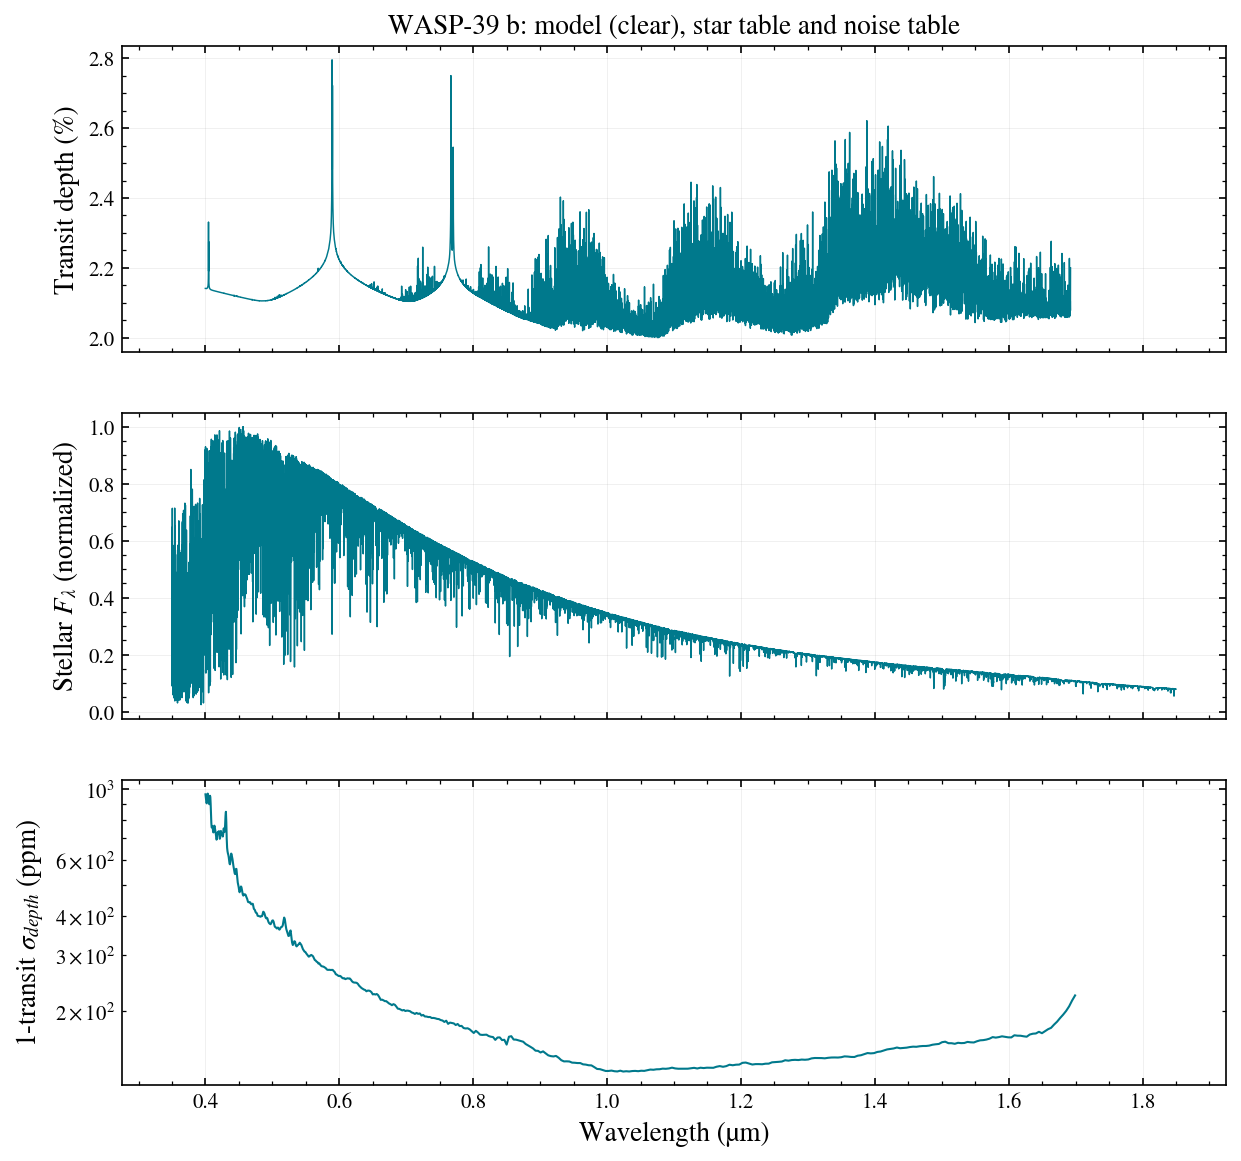

star grid: phoenix, T_eff = 5485.0 K, units = POSEIDON F_star (W/m^2/m)


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)

axes[0].plot(wl_m, depth_m * 100.0, lw=0.7)
axes[0].set_ylabel("Transit depth (%)")
axes[0].set_title(f"{PLANET}: model (clear), star table and noise table")

axes[1].plot(wl_s, flam_s / flam_s.max(), lw=0.7)
axes[1].set_ylabel("Stellar $F_\\lambda$ (normalized)")

axes[2].plot(wl_n, err_n * 1e6, lw=1.0)
axes[2].set_ylabel("1-transit $\\sigma_{depth}$ (ppm)")
axes[2].set_yscale("log")
axes[2].set_xlabel("Wavelength (µm)")

plt.show()

print(f"star grid: {meta_s['stellar_grid']}, "
      f"T_eff = {meta_s['T_eff_K']} K, units = {meta_s['units']}")

## What the noise table records

The noise `meta` is the provenance of every error bar: the instrument, the
normalization band and the Vega to AB conversion, the readout actually used, the
assumption the depth uncertainty rests on, and the package version, git commit
and input hashes the table was generated from.

In [7]:
for k, v in meta_n.items():
    print(f"  {k:28s} {v}")

  generator                    make_noise_tables.py
  created                      2026-10-11
  J_mag                        10.663
  norm_band                    2massj
  stellar_grid                 phoenix_grid.npz solar [Fe/H]
  star                         {'fallback': None, 'clamped': {'feh': [0.01, 0.0]}, 'teff_K': 5485.0, 'teff_used': 5485.0, 'logg_used': 4.453, 'feh_used': 0.0, 'grid': 'phoenix'}
  slicersim_version            1.3.4
  instrument                   lazuli_cbe
  t_int_s                      45.28
  default_nmd                  [16, 8, 0]
  nmd_used                     [2, 8, 0]
  nramps                       1
  readout_mode                 auto
  tframe_s                     2.83
  spectrograph_mode            narrow
  guiding_sigma                None
  zodi_ab_mag                  None
  nsaturated_detpx             0
  fully_desaturated            True
  nsaturated_detpx_slicersim   0
  band                         J
  sncosmo_band                 2massj
  ma

## Noise vs. host brightness

Single-transit depth precision is driven mostly by how bright the host is.
Plotting the median against the registry's J magnitude shows the photon-limited
trend, with the sub-Neptune and terrestrial hosts at the faint end.

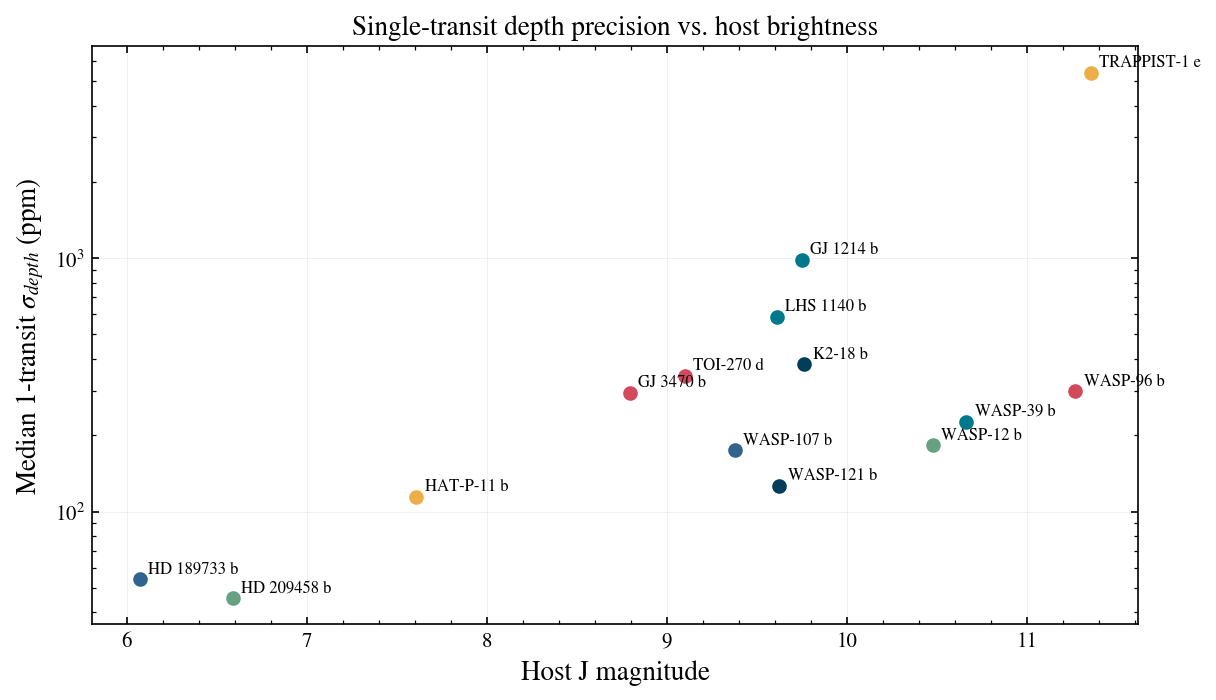

In [8]:
from lazuli_exo.targets import get_target

rows = []
for p in lazuli_exo.list_planets():
    _, e, _ = tables.load_noise(tdir, p)
    rows.append((p, get_target(p)["J_mag"], np.median(e)))

fig, ax = plt.subplots(figsize=(9, 5))
for p, j, e in rows:
    ax.plot(j, e * 1e6, "o", ms=6)
    ax.annotate(p, (j, e * 1e6), fontsize=8,
                xytext=(4, 3), textcoords="offset points")

ax.set_yscale("log")
ax.set_xlabel("Host J magnitude")
ax.set_ylabel("Median 1-transit $\\sigma_{depth}$ (ppm)")
ax.set_title("Single-transit depth precision vs. host brightness")
plt.show()

## The target registry

`lazuli_exo.targets` is a frozen snapshot of the NASA Exoplanet Archive
`PSCompPars` table (plus a few overrides), generated by
`precompute/freeze_targets.py`. It is a plain dict: no network access at runtime
and no dependency on the archive being up.

In [9]:
fields = ["T_eq_K", "R_p_RJ", "R_s_RSun", "T_eff_K", "J_mag",
          "period_d", "a_over_rs", "inc_deg", "depth"]

print(f"{'planet':14s}" + "".join(f"{f:>11s}" for f in fields))
for p in lazuli_exo.list_planets():
    t = get_target(p)
    print(f"{p:14s}" + "".join(f"{t[f]:11.4g}" for f in fields))

planet             T_eq_K     R_p_RJ   R_s_RSun    T_eff_K      J_mag   period_d  a_over_rs    inc_deg      depth
GJ 1214 b             567     0.2438     0.2162       3101       9.75       1.58      14.97      88.98    0.01343
GJ 3470 b           593.5     0.4068      0.547       3600      8.794      3.337      13.98      89.13    0.00584
HAT-P-11 b            838     0.3854      0.683       4653      7.608      4.888      16.72      89.03   0.003363
HD 189733 b          1209      1.134       0.75       5052      6.073      2.219       8.84      85.71    0.02413
HD 209458 b          1459        1.4       1.19       6091      6.591      3.525       8.81      86.71    0.01461
K2-18 b               284      0.215      0.411       3457      9.763      32.94      83.83      89.58   0.002889
LHS 1140 b            226     0.1553     0.2159       3096      9.612      24.74      95.34      89.86   0.005461
TOI-270 d             383     0.1816       0.38       3506      9.099      11.38      41

In [10]:
t = get_target("K2-18 b")
print("full registry entry for K2-18 b:\n")
for k, v in sorted(t.items()):
    print(f"  {k:12s} {v}")

full registry entry for K2-18 b:

  J_mag        9.763
  M_p_MJ       0.02806532
  Met_star     0.12
  R_p_RJ       0.2149734603172383
  R_p_archive_RJ 0.21143724
  R_s_RSun     0.411
  T_eff_K      3457.0
  T_eq_K       284.0
  T_eq_conv_K  266.9836392529934
  a_over_rs    83.83
  depth        0.0028890624999999997
  ecc          0.2
  inc_deg      89.5785
  k_source     pl_ratror
  log_g_star   4.7864
  name         K2-18 b
  period_d     32.939623
  provenance   NEA PSCompPars
  slug         k2-18-b
  t14_s        9655.199999999999
  w_deg        -5.7


Unknown names fail loudly, listing what is available. `observe()` behaves the
same way for an unknown planet or scenario.

In [11]:
for call, label in [
    (lambda: get_target("Kepler-999 b"), "get_target"),
    (lambda: lazuli_exo.observe("Kepler-999 b", "clear", tables_dir=tdir), "observe"),
    (lambda: lazuli_exo.observe("WASP-39 b", "stormy", tables_dir=tdir), "scenario"),
]:
    try:
        call()
    except KeyError as exc:
        print(f"{label:12s} KeyError: {str(exc)[:88]}...")
    else:
        raise AssertionError(f"{label} should have raised")

get_target   KeyError: "Unknown target 'Kepler-999 b'. Available: ['GJ 1214 b', 'GJ 3470 b', 'HAT-P-11 b', 'HD ...
observe      KeyError: "Unknown target 'Kepler-999 b'. Available: ['GJ 1214 b', 'GJ 3470 b', 'HAT-P-11 b', 'HD ...
scenario     KeyError: "Unknown scenario 'stormy'. Available: ['clear', 'cloudy', 'flat', 'hazy', 'high_metalli...


## The saturation caveat

The brightest hosts push the detector toward saturation. slicersim shortens the
readout until the ramp is clean, and when even the shortest ramp (2 groups x 1
frame) leaves saturated pixels at the last read, the residual count is recorded
in the noise table and `observe()` raises a `UserWarning`. With the current
tables one host is affected.

<div class="alert alert-warning">

For a flagged target the uncertainties are unvalidated: saturation can bias
extraction weights, nonlinearity and wavelength dependence in either direction.
Treat its forecasts as indicative only. Check the flag in the data rather than
remembering a name; the list changes when the tables are regenerated.

</div>

In [12]:
print(f"{'planet':14s}{'desaturated':>13s}{'saturated px':>14s}"
      f"{'nmd used':>10s}")
flagged = []
for p in lazuli_exo.list_planets():
    _, _, m = tables.load_noise(tdir, p)
    ok = m.get("fully_desaturated")
    if ok is False:
        flagged.append(p)
    print(f"{p:14s}{str(ok):>13s}{m.get('nsaturated_detpx', 0):14d}"
          f"{str(m.get('nmd_used')):>10s}")

print(f"\nflagged: {flagged}")

planet          desaturated  saturated px  nmd used
GJ 1214 b              True             0 [2, 4, 0]
GJ 3470 b              True             0 [2, 2, 0]
HAT-P-11 b             True             0 [2, 1, 0]
HD 189733 b           False           324 [2, 1, 0]
HD 209458 b            True             0 [2, 1, 0]
K2-18 b                True             0 [2, 4, 0]
LHS 1140 b             True             0 [2, 4, 0]
TOI-270 d              True             0 [2, 2, 0]
TRAPPIST-1 e           True             0 [4, 8, 0]


WASP-107 b             True             0 [2, 4, 0]
WASP-12 b              True             0 [2, 8, 0]


WASP-121 b             True             0 [2, 4, 0]
WASP-39 b              True             0 [2, 8, 0]
WASP-96 b              True             0 [4, 8, 0]

flagged: ['HD 189733 b']


In [13]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    lazuli_exo.observe(flagged[0], scenario="clear", n_transits=1)

for w in caught:
    print(f"{w.category.__name__}: {w.message}")

assert caught and caught[0].category is UserWarning

## Pointing at a different tables directory

For a deployment that keeps the tables elsewhere, set `LAZULI_EXO_TABLES` or
pass `tables_dir=` per call. Both take precedence over the packaged default, in
that order.

In [14]:
import os

print(f"default (package-relative): {tables.resolve_tables_dir(None)}")
print(f"explicit argument:          "
      f"{tables.resolve_tables_dir('/some/other/tables')}")

os.environ["LAZULI_EXO_TABLES"] = "/from/the/environment"
print(f"from $LAZULI_EXO_TABLES:    {tables.resolve_tables_dir(None)}")
del os.environ["LAZULI_EXO_TABLES"]

# an explicit argument still wins over the environment variable
os.environ["LAZULI_EXO_TABLES"] = "/from/the/environment"
print(f"argument beats env:         "
      f"{tables.resolve_tables_dir('/explicit/wins')}")
del os.environ["LAZULI_EXO_TABLES"]

# observe() takes the same argument
obs = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1,
                         tables_dir=tdir)
print(f"\nobs.meta['tables_dir']:     {obs.meta['tables_dir']}")

default (package-relative): /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/data/tables
explicit argument:          /some/other/tables
from $LAZULI_EXO_TABLES:    /from/the/environment
argument beats env:         /explicit/wins

obs.meta['tables_dir']:     /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/data/tables


## Summary

- Per-planet star, noise and limb-darkening tables plus two grids (ζ and
  PHOENIX) under one directory, catalogued by a version-stamped `index.json`
  with a sha256 manifest that `rebuild_index()` regenerates from disk.
- Every table carries a `meta` dict recording how it was produced: stellar
  grid, readout mode, LD grid point, package version and git commit.
- The registry (`lazuli_exo.targets`) is a frozen NEA snapshot; no network at
  runtime.
- The caveats live in the data: `T_clamped` in `meta["atmosphere"]` on cold
  planets, `fully_desaturated` in the noise table on bright hosts (which also
  raises a `UserWarning`).
- `tables_dir=` beats `$LAZULI_EXO_TABLES` beats the packaged default.

That covers the showcase tables. Notebooks 6 to 9 cover the parametric model:
any planet from a dozen numbers, with the noise computed live.